In [8]:
import sys
import os
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [9]:
figure_output_dir = Path('../4_manuscript_figures/')

In [10]:
clinvar_parquet = Path("../../4_compare_AI_scores/3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants_plddt_rsa.parquet")

In [11]:
clinvar_df = pd.read_parquet(clinvar_parquet)
clinvar_df

,clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),...,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,plddt,rsa
0,2361281,21,13628442,G,T,S,I,rs905107791,21,15000763,...,-,-,1187G>T,Ser396Ile,NC_000021.9:13628442:G:T,NM_174981.6,1.0,4_VUS,32.34,0.953846
1,2599176,21,13630941,G,T,V,F,rs937658823,21,15003262,...,-,-,1243G>T,Val415Phe,NC_000021.9:13630941:G:T,NM_174981.6,1.0,4_VUS,58.03,0.063380
2,2486768,21,13630977,G,A,V,M,.,21,15003298,...,-,-,1279G>A,Val427Met,NC_000021.9:13630977:G:A,NM_174981.6,1.0,2_Benign,32.90,0.978873
3,2277922,21,13631057,A,C,R,S,.,21,15003378,...,-,-,1359A>C,Arg453Ser,NC_000021.9:13631057:A:C,NM_174981.6,1.0,4_VUS,31.88,0.995968
4,3308991,21,13639588,A,T,T,S,.,21,15011909,...,-,-,1483A>T,Thr495Ser,NC_000021.9:13639588:A:T,NM_174981.6,1.0,4_VUS,75.35,0.492958
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1649575,999991,9,35089109,G,T,L,M,rs1829299184,9,35089106,...,-,-,3253C>A,Leu1085Met,NC_000009.12:35089109:G:T,NM_032634.4,1.0,4_VUS,64.13,0.524390
1649576,999992,3,50379584,C,T,E,K,rs743855,3,50417015,...,-,-,1000G>A,Glu334Lys,NC_000003.12:50379584:C:T,NM_006030.4,1.0,4_VUS,91.87,0.525773
1649577,999993,10,101023538,C,T,G,D,rs1853249107,10,102783295,...,-,-,440G>A,Gly147Asp,NC_000010.11:101023538:C:T,NM_001195263.2,1.0,4_VUS,89.78,0.547619
1649578,999994,5,55941246,T,C,M,V,rs761846914,5,55237074,...,-,-,2593A>G,Met865Val,NC_000005.10:55941246:T:C,NM_002184.4,1.0,4_VUS,24.77,1.000000


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_19519/1822659887.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clinvar_df['Year'] = clinvar_df[date_col].dt.year
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_19519/1822659887.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clinvar_df


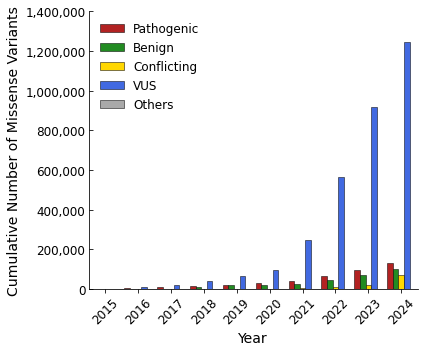

In [12]:
def plot_clinvar(clinvar_df, save_fig=False):
    
    date_col = 'LastEvaluated'

    # Convert LastEvaluated to datetime, forcing invalid to become NaT
    clinvar_df[date_col] = pd.to_datetime(clinvar_df[date_col], errors='coerce')

    # Drop rows where LastEvaluated couldn't be parsed (NaT)
    clinvar_df = clinvar_df.dropna(subset=[date_col])
    
    clinsig_col = 'clinvar_clnsig_clean'

    # Extract year
    clinvar_df['Year'] = clinvar_df[date_col].dt.year

    # Group by Year and ClinSig
    yearly_counts = (
        clinvar_df
        .groupby(['Year', clinsig_col])
        .size()
        .unstack(fill_value=0)
    )

    # Sort the index by year
    yearly_counts = yearly_counts.sort_index()

    # Only show rows from 2015 and after
    yearly_counts = yearly_counts.loc[
        (yearly_counts.index >= 2015) & 
        (yearly_counts.index <= 2024)]

    # Reorder columns if needed
    desired_order = ['1_Pathogenic', '2_Benign', '3_Conflicting', '4_VUS', '5_Others']
    yearly_counts = yearly_counts[[col for col in desired_order if col in yearly_counts.columns]]

    # Cumulative counts
    yearly_cum_counts = yearly_counts.cumsum()

    # Color mapping
    color_map = {
        '2_Benign': 'forestgreen',
        '1_Pathogenic': 'firebrick',
        '4_VUS': 'royalblue',
        '3_Conflicting': 'gold',
        '5_Others': 'darkgray'
    }

    fig, ax = plt.subplots(figsize=(6,5))

    # Plot
    ax = yearly_cum_counts.plot(
        kind='bar',
        ax=ax,
        width=0.85,
        stacked=False,
        color=[color_map.get(col, 'gray') for col in yearly_cum_counts.columns],
        edgecolor='black',
        linewidth=0.5
    )

    # Tighten x-limits so there's minimal extra space
    num_years = len(yearly_cum_counts.index)
    ax.set_xlim(-0.5, num_years - 0.5)

    # Set integer x-ticks and labels
    ax.set_xticks(range(num_years))
    ax.set_xticklabels(yearly_cum_counts.index, rotation=45)

    # Format large y-values with commas, no scientific notation
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

    # Increase tick label size
    ax.tick_params(axis='both', labelsize=12)


    ax.spines['left'].set_visible(True)          # Ensure the left spine is visible
    ax.spines['right'].set_visible(False)        # Hide the right spine if you like
    ax.yaxis.set_label_position("left")          # Keep the axis label on the left
    ax.yaxis.set_ticks_position("left")          # Ticks on the left spine

    # direction='in' => tick marks go inside the plot
    ax.tick_params(axis='y', direction='in')

    # Remove the top spine if desired
    ax.spines['top'].set_visible(False)

    # Axis labels & title
    ax.set_xlabel("Year", fontsize=14)
    ax.set_ylabel("Cumulative Number of Missense Variants", fontsize=14)
    # ax.set_title("Clinical Significance of Missense Variants over the Years", fontsize=14)
    
    # New legend without the prefix
    handles, labels = ax.get_legend_handles_labels()
    new_labels = [label.split('_', 1)[1] for label in labels]
    ax.legend(handles, new_labels, title="", fontsize=12, frameon=False, loc='upper left')


    ticks = ax.get_yticks()

    # Set the top limit to the last tick
    ax.set_ylim(top=ticks[-1])

    plt.tight_layout()
    
    if save_fig:
        plt.savefig(figure_output_dir / "clinvar_missense_variants_clinical_significance_year.png", dpi=300)
        
    plt.show()
    
    
plot_clinvar(clinvar_df, save_fig=True)